# COMP6010 Practical 7: Diffusion and Flow Matching Models
**Student Name:** Satria Said  
**Unit:** Planning and Handling Uncertainty in Machine Learning (COMP6010)  
**Topic:** Continuous Normalizing Flows, Flow Matching, Reverse Diffusion, and Classifier-Free Guidance

---

## Practical Overview & Learning Objectives
In this practical, we explore modern continuous generative models, specifically comparing **Diffusion Models** and **Flow Matching**:
1. **Flow Matching & Inverse Flow (Question 1):** Learn how a neural vector field transports Gaussian noise $\mathcal{N}(0, I)$ to a complex data distribution (two-moons) via Ordinary Differential Equations (ODEs), implement the **inverse flow** back to noise, and perform round-trip error analysis.
2. **Statistical Denoising & Tweedie's Formula (Question 2):** Understand why noise removal is fundamentally an ill-posed single-observation problem that becomes solvable through Bayesian priors and score-based drift.
3. **Reverse Diffusion Mechanics (Question 3):** Dissect why forward diffusion is trivial while reverse diffusion requires estimating the clean sample $x_0$ or score.
4. **Classifier-Free Guidance (Question 4):** Derive and interpret the score-based guidance formulation that powers modern image generation (e.g., Stable Diffusion, Midjourney, FLUX).

--- 
## 0. Setup and Imports
We import PyTorch for neural network definitions and tensor operations, `matplotlib` for visualization, and `scikit-learn` for generating the target two-moons distribution.

In [1]:
import torch 
from torch import nn, Tensor
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch Version: {torch.__version__}")

PyTorch Version: 2.14.0+cpu


--- 
## 1. Flow Matching Network & Numerical ODE Solver

### Continuous Normalizing Flows (CNF) & Flow Matching
Flow Matching models a continuous transformation of particles over time $t \in [0, 1]$.
- At $t = 0$, particles are distributed according to a simple base distribution (standard normal noise $x_0 \sim \mathcal{N}(0, I)$).
- At $t = 1$, particles are distributed according to the target data distribution $x_1 \sim p_{\text{data}}$ (the two-moons dataset).
- The trajectory between source $x_0$ and target $x_1$ is defined by a straight-line interpolation:
  $$x_t = (1 - t)x_0 + t x_1$$
- The instantaneous velocity (time derivative) along this path is constant:
  $$u_t(x_t \mid x_0, x_1) = \frac{d x_t}{dt} = x_1 - x_0$$

### Neural Vector Field Architecture (`Flow`)
The neural network $v_\theta(t, x_t)$ takes the current time $t \in [0, 1]$ and position $x_t \in \mathbb{R}^2$, concatenating them into a 3D input vector $[t, x_t^1, x_t^2]$, and outputs the predicted 2D velocity vector $\hat{v} \in \mathbb{R}^2$.

### Numerical Integration (`step`)
To solve the initial value problem $\frac{dx}{dt} = v_\theta(t, x)$, the `step` method implements the **Explicit Midpoint Method (2nd-order Runge-Kutta / RK2)**:
$$\Delta t = t_{\text{end}} - t_{\text{start}}$$
$$k_1 = v_\theta(t_{\text{start}}, x_t)$$
$$x_{\text{mid}} = x_t + k_1 \cdot \frac{\Delta t}{2}$$
$$t_{\text{mid}} = t_{\text{start}} + \frac{\Delta t}{2}$$
$$k_2 = v_\theta(t_{\text{mid}}, x_{\text{mid}})$$
$$x_{\text{next}} = x_t + \Delta t \cdot k_2$$
This achieves a local truncation error of $\mathcal{O}(\Delta t^3)$ and global error of $\mathcal{O}(\Delta t^2)$.

In [2]:
class Flow(nn.Module):
    def __init__(self, dim: int = 2, h: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim + 1, h), nn.ELU(),
            nn.Linear(h, h), nn.ELU(),
            nn.Linear(h, h), nn.ELU(),
            nn.Linear(h, dim)
        )
    
    def forward(self, t: Tensor, x_t: Tensor) -> Tensor:
        """Predicts the velocity vector field v_theta(t, x_t)."""
        return self.net(torch.cat((t, x_t), -1))
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        """
        Integrates the ODE dx/dt = v_theta(t, x_t) from t_start to t_end using 
        the 2nd-order Runge-Kutta (Midpoint) numerical integrator.
        Works for both forward (t_start < t_end) and backward (t_start > t_end) steps.
        """
        dt = t_end - t_start
        t_start_vec = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt_vec = dt.view(1, 1).expand(x_t.shape[0], 1)
        
        # k1: initial slope
        k1 = self(t=t_start_vec, x_t=x_t)
        
        # Midpoint state and time
        x_mid = x_t + k1 * (dt_vec / 2.0)
        t_mid = t_start_vec + (dt_vec / 2.0)
        
        # k2: slope evaluated at the midpoint
        k2 = self(t=t_mid, x_t=x_mid)
        
        # Final update step
        return x_t + dt_vec * k2

--- 
## 2. Model Training (Conditional Flow Matching)
During training, for each iteration:
1. Draw a batch of data points $x_1 \sim p_{\text{data}}$ from `make_moons`.
2. Draw a batch of independent Gaussian noise vectors $x_0 \sim \mathcal{N}(0, I)$.
3. Sample random continuous time points $t \sim \mathcal{U}(0, 1)$.
4. Form the interpolated points $x_t = (1 - t)x_0 + t x_1$.
5. Compute target velocity $u_t = x_1 - x_0$.
6. Optimize the network by minimizing the Mean Squared Error (MSE):
   $$\mathcal{L}_{\text{CFM}}(\theta) = \mathbb{E}_{t, x_0, x_1} \left[ \| v_\theta(t, x_t) - (x_1 - x_0) \|^2 \right]$$

In [3]:
flow = Flow()
optimizer = torch.optim.Adam(flow.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

num_iterations = 10000
print_every = 2000
losses = []

print("Starting Flow Matching training...")
for it in range(1, num_iterations + 1):
    # 1. Sample clean data x_1
    x_1 = Tensor(make_moons(256, noise=0.05)[0])
    # 2. Sample Gaussian noise x_0
    x_0 = torch.randn_like(x_1)
    # 3. Sample random time t in [0, 1]
    t = torch.rand(len(x_1), 1)
    
    # 4. Straight-line interpolation x_t
    x_t = (1.0 - t) * x_0 + t * x_1
    # 5. Target velocity
    dx_t = x_1 - x_0
    
    # 6. Gradient update
    optimizer.zero_grad()
    pred_v = flow(t=t, x_t=x_t)
    loss = loss_fn(pred_v, dx_t)
    loss.backward()
    optimizer.step()
    
    losses.append(loss.item())
    if it % print_every == 0 or it == 1:
        print(f"Iteration {it:5d}/{num_iterations} | Loss: {loss.item():.5f}")

print("Training completed successfully!")

Starting Flow Matching training...
Iteration     1/10000 | Loss: 1.74646
Iteration  2000/10000 | Loss: 1.06691
Iteration  4000/10000 | Loss: 1.02330
Iteration  6000/10000 | Loss: 0.97467
Iteration  8000/10000 | Loss: 1.11347
Iteration 10000/10000 | Loss: 0.83421
Training completed successfully!


--- 
## 3. Forward Sampling ($t = 0 \to t = 1$)
To generate new samples, we start with 300 random Gaussian points at $t = 0$ and integrate the learned vector field forward to $t = 1$ across 8 equal steps using `flow.step`.

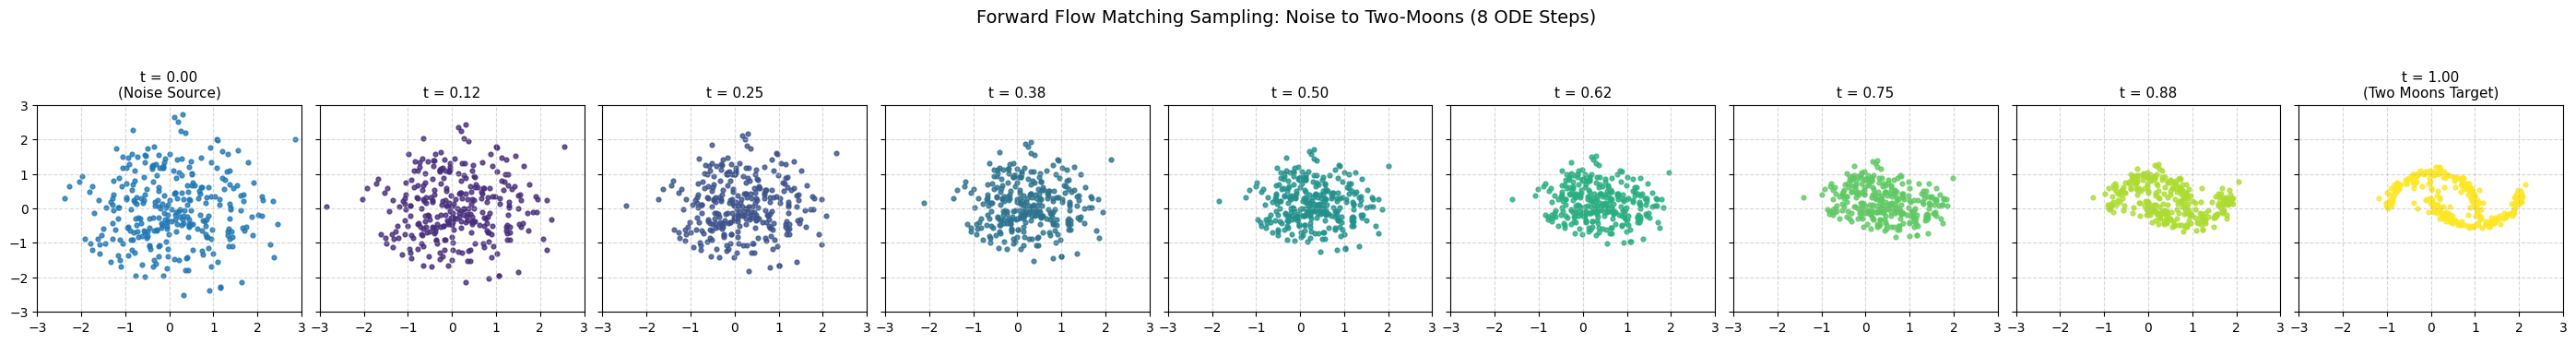

In [4]:
n_samples = 300
n_steps = 8

# Start from Gaussian noise at t=0
x_init = torch.randn(n_samples, 2)
x = x_init.clone()
time_steps = torch.linspace(0.0, 1.0, n_steps + 1)

fig, axes = plt.subplots(1, n_steps + 1, figsize=(28, 3.5), sharex=True, sharey=True)

axes[0].scatter(x.detach()[:, 0], x.detach()[:, 1], s=12, color='#1f77b4', alpha=0.8)
axes[0].set_title(f"t = {time_steps[0]:.2f}\n(Noise Source)", fontsize=11)
axes[0].set_xlim(-3.0, 3.0)
axes[0].set_ylim(-3.0, 3.0)
axes[0].grid(True, linestyle="--", alpha=0.5)

for i in range(n_steps):
    t_start = time_steps[i]
    t_end = time_steps[i + 1]
    x = flow.step(x_t=x, t_start=t_start, t_end=t_end)
    
    ax = axes[i + 1]
    color = plt.cm.viridis((i + 1) / n_steps)
    ax.scatter(x.detach()[:, 0], x.detach()[:, 1], s=12, color=color, alpha=0.8)
    title_label = f"t = {t_end:.2f}" if i < n_steps - 1 else f"t = {t_end:.2f}\n(Two Moons Target)"
    ax.set_title(title_label, fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Forward Flow Matching Sampling: Noise to Two-Moons (8 ODE Steps)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

---
# Question 1: Flow Matching and the Inverse Flow

### (a) Training and Sampling Description

**1. The Source Point $x_0$:**
- An unstructured Gaussian noise sample drawn from the standard normal prior distribution: $x_0 \sim \mathcal{N}(0, I)$. In the code: `x_0 = torch.randn_like(x_1)`.

**2. The Target/Data Point $x_1$:**
- A clean sample drawn from the empirical target data distribution $p_{\text{data}}$. In the code, this is drawn from the two-moons dataset: `x_1 = Tensor(make_moons(256, noise=0.05)[0])`.

**3. The Interpolated Point $x_t$:**
- The linear mixture of the source noise point $x_0$ and target point $x_1$ at continuous time $t \in [0, 1]$:
  $$x_t = (1 - t)x_0 + t x_1$$
  This defines a straight conditional probability path from $x_0$ at $t=0$ to $x_1$ at $t=1$.

**4. The Target Velocity Used for Training:**
- The exact time derivative along the conditional straight-line path:
  $$u_t(x_t \mid x_0, x_1) = \frac{d x_t}{dt} = \frac{d}{dt} \left[ (1 - t)x_0 + t x_1 \right] = x_1 - x_0$$
  In the code: `dx_t = x_1 - x_0`. Notice that this conditional velocity is constant with respect to time $t$ for any paired trajectory.

**5. The Quantity Predicted by the Neural Network:**
- The marginal vector field $v_\theta(t, x_t) \in \mathbb{R}^2$, representing the expected instantaneous velocity of any particle currently located at position $x_t$ and time $t$, averaged over all pairs of $(x_0, x_1)$ passing through that point:
  $$v_\theta(t, x_t) \approx \mathbb{E}\left[ x_1 - x_0 \mid x_t \right]$$

**How the Trained Model Generates New Data Samples:**
- To sample, we draw an initial noise particle from the standard normal distribution $x(0) = z \sim \mathcal{N}(0, I)$ at $t = 0$.
- We integrate the initial value problem (ODE) $\frac{dx}{dt} = v_\theta(t, x)$ from $t = 0$ to $t = 1$ using a numerical solver (e.g., the midpoint method `flow.step` with $N$ discrete steps $\Delta t = 1/N$).
- As the particles flow along the learned vector field, their collective distribution smoothly deforms from standard Gaussian noise into the two-moons data distribution.

---
### (b) Implement the Inverse Flow with LLM Assistance

**Theoretical Foundation of Inverse Flow:**
A continuous flow is governed by the deterministic ordinary differential equation:
$$\frac{dx}{dt} = v_\theta(t, x)$$
Because ODEs are inherently time-reversible, integrating the **same velocity field** backward in time from $t = 1$ to $t = 0$ reverses the dynamics:
$$x(0) = x(1) + \int_{1}^{0} v_\theta(t, x(t)) \, dt = x(1) - \int_{0}^{1} v_\theta(t, x(t)) \, dt$$
We do **not** need to train a new network! We use the identical learned neural vector field $v_\theta(t, x)$.

In the midpoint implementation (`flow.step`), we simply pass a reversed time sequence where $t_{\text{start}} > t_{\text{end}}$, meaning $\Delta t = t_{\text{end}} - t_{\text{start}} < 0$. The step method naturally handles this negative increment and moves backwards along the velocity field.

**LLM Assistance Reflection:**
- *Prompt/Idea obtained from the LLM:* "To invert an ODE flow $\frac{dx}{dt} = v_\theta(t, x)$, you do not train an inverse model. Instead, recognize that $\int_1^0 v_\theta dt = -\int_0^1 v_\theta dt$. In a Runge-Kutta or midpoint solver, stepping with negative $\Delta t$ from $t=1$ down to $t=0$ automatically solves the inverse initial value problem, exactly unwinding the transformation."

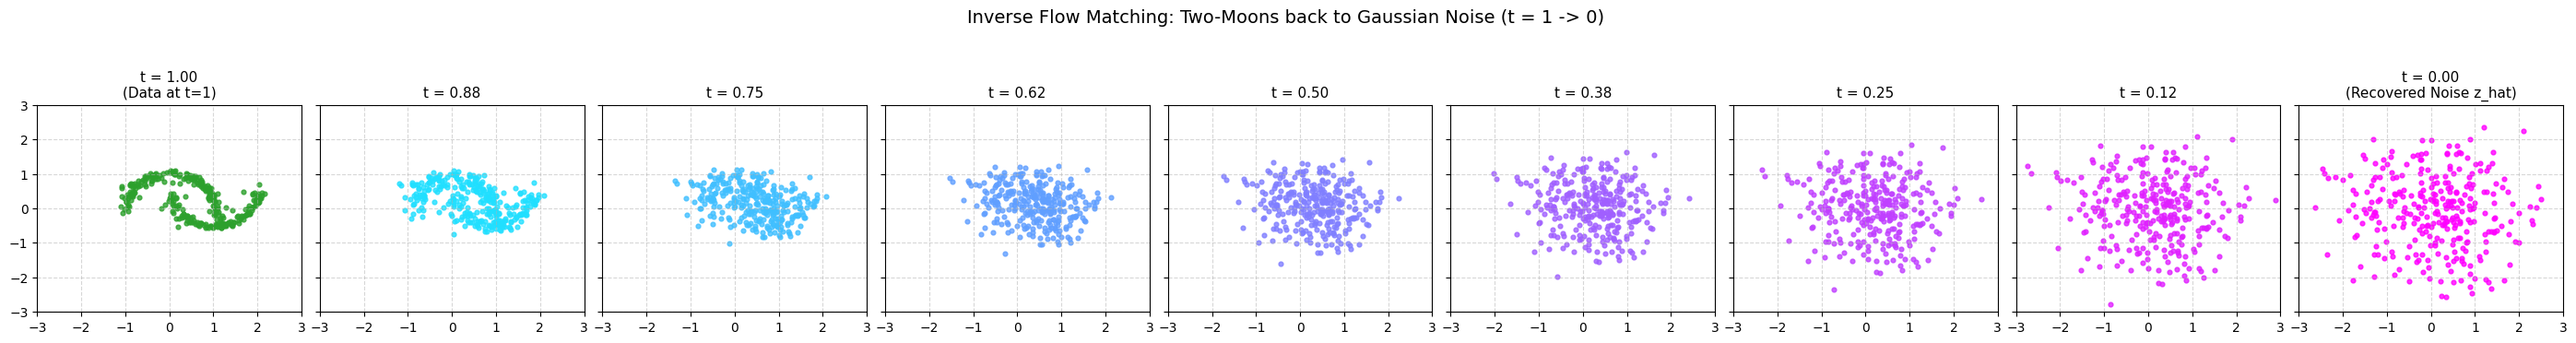

In [5]:
# Generate points at t=1 using forward flow, then invert back to t=0
n_test_samples = 300
n_ode_steps = 8

# 1. Forward generation: t = 0 to t = 1
z_source = torch.randn(n_test_samples, 2)
x_curr = z_source.clone()
forward_times = torch.linspace(0.0, 1.0, n_ode_steps + 1)

for i in range(n_ode_steps):
    x_curr = flow.step(x_t=x_curr, t_start=forward_times[i], t_end=forward_times[i + 1])

x_generated_data = x_curr.clone() # Points at t = 1 (Two Moons)

# 2. Inverse Flow: t = 1 back to t = 0 using the EXACT same flow network
backward_times = torch.linspace(1.0, 0.0, n_ode_steps + 1)
x_inv = x_generated_data.clone()

fig, axes = plt.subplots(1, n_ode_steps + 1, figsize=(28, 3.5), sharex=True, sharey=True)

axes[0].scatter(x_inv.detach()[:, 0], x_inv.detach()[:, 1], s=12, color='#2ca02c', alpha=0.8)
axes[0].set_title(f"t = {backward_times[0]:.2f}\n(Data at t=1)", fontsize=11)
axes[0].set_xlim(-3.0, 3.0)
axes[0].set_ylim(-3.0, 3.0)
axes[0].grid(True, linestyle="--", alpha=0.5)

for i in range(n_ode_steps):
    t_start = backward_times[i]
    t_end = backward_times[i + 1] # Note: t_end < t_start, so dt < 0
    x_inv = flow.step(x_t=x_inv, t_start=t_start, t_end=t_end)
    
    ax = axes[i + 1]
    color = plt.cm.cool((i + 1) / n_ode_steps)
    ax.scatter(x_inv.detach()[:, 0], x_inv.detach()[:, 1], s=12, color=color, alpha=0.8)
    title_label = f"t = {t_end:.2f}" if i < n_ode_steps - 1 else f"t = {t_end:.2f}\n(Recovered Noise z_hat)"
    ax.set_title(title_label, fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Inverse Flow Matching: Two-Moons back to Gaussian Noise (t = 1 -> 0)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

---
### (c) Round-Trip Test: $z \xrightarrow{\text{forward}} x_1 \xrightarrow{\text{inverse}} \hat{z}$
We test the fidelity of the round-trip operation by:
1. Generating initial Gaussian source points $z$.
2. Transporting forward to $x_1$ via 8 ODE steps from $t = 0 \to 1$.
3. Transporting $x_1$ backward to $\hat{z}$ via 8 ODE steps from $t = 1 \to 0$.
4. Plotting $z$ and $\hat{z}$ and computing the Mean Squared Error:
   $$\text{MSE}(z, \hat{z}) = \frac{1}{N} \sum_{i=1}^N \| z_i - \hat{z}_i \|^2$$

ROUND-TRIP TEST RESULTS (N = 8 steps):
Mean Squared Error MSE(z, z_hat): 1.345322e-03
Maximum L2 error:                 2.254665e-01


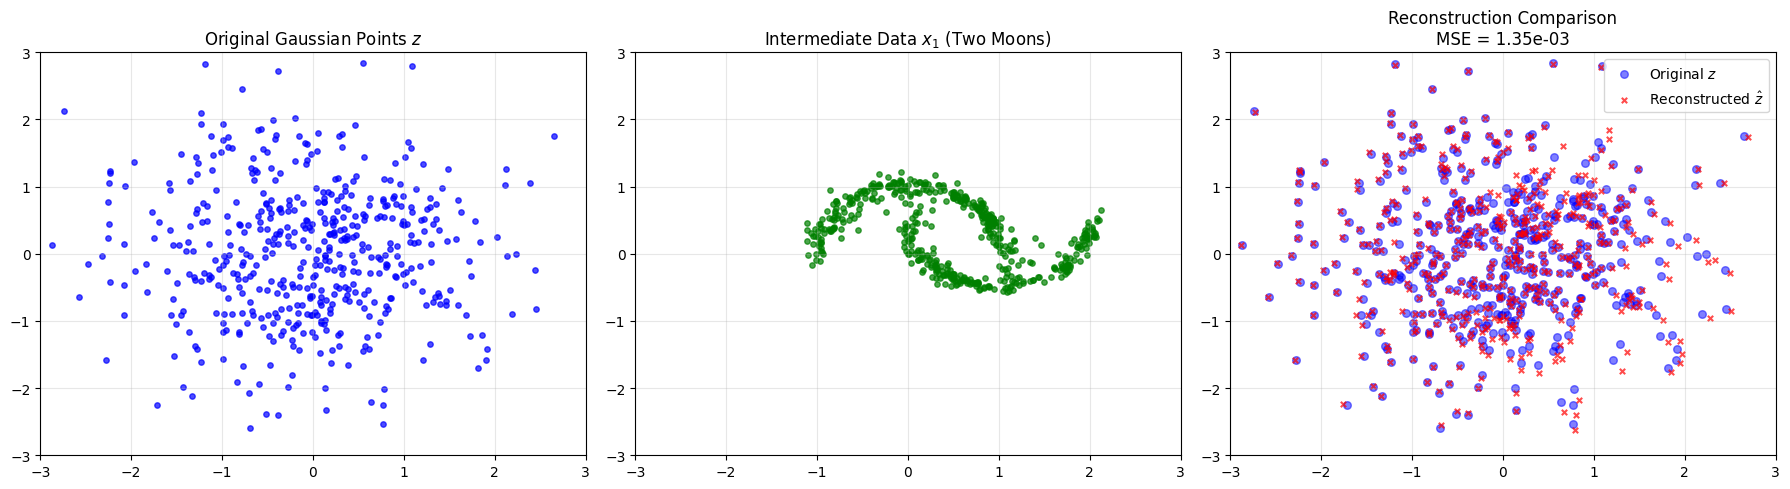

In [6]:
# Round-trip test implementation
n_round_trip = 500
n_steps = 8

# Step 1: Initial Gaussian points z
z = torch.randn(n_round_trip, 2)

# Step 2: Forward flow (z -> x1)
fwd_times = torch.linspace(0.0, 1.0, n_steps + 1)
x_fwd = z.clone()
for i in range(n_steps):
    x_fwd = flow.step(x_t=x_fwd, t_start=fwd_times[i], t_end=fwd_times[i + 1])
x1 = x_fwd.clone()

# Step 3: Inverse flow (x1 -> z_hat)
bwd_times = torch.linspace(1.0, 0.0, n_steps + 1)
x_bwd = x1.clone()
for i in range(n_steps):
    x_bwd = flow.step(x_t=x_bwd, t_start=bwd_times[i], t_end=bwd_times[i + 1])
z_hat = x_bwd.clone()

# Step 4: Calculate MSE(z, z_hat)
mse_round_trip = torch.mean((z - z_hat) ** 2).item()
max_err = torch.max(torch.norm(z - z_hat, dim=-1)).item()

print("="*50)
print(f"ROUND-TRIP TEST RESULTS (N = {n_steps} steps):")
print(f"Mean Squared Error MSE(z, z_hat): {mse_round_trip:.6e}")
print(f"Maximum L2 error:                 {max_err:.6e}")
print("="*50)

# Plotting z and z_hat
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Original z
axes[0].scatter(z[:, 0].numpy(), z[:, 1].numpy(), s=15, alpha=0.7, color='blue')
axes[0].set_title("Original Gaussian Points $z$", fontsize=12)
axes[0].set_xlim(-3.0, 3.0); axes[0].set_ylim(-3.0, 3.0); axes[0].grid(True, alpha=0.3)

# Subplot 2: Generated data x1
axes[1].scatter(x1[:, 0].detach().numpy(), x1[:, 1].detach().numpy(), s=15, alpha=0.7, color='green')
axes[1].set_title("Intermediate Data $x_1$ (Two Moons)", fontsize=12)
axes[1].set_xlim(-3.0, 3.0); axes[1].set_ylim(-3.0, 3.0); axes[1].grid(True, alpha=0.3)

# Subplot 3: Comparison z vs z_hat
axes[2].scatter(z[:, 0].numpy(), z[:, 1].numpy(), s=30, alpha=0.5, color='blue', label="Original $z$")
axes[2].scatter(z_hat[:, 0].detach().numpy(), z_hat[:, 1].detach().numpy(), s=15, alpha=0.7, color='red', marker='x', label="Reconstructed $\\hat{z}$")
axes[2].set_title(f"Reconstruction Comparison\nMSE = {mse_round_trip:.2e}", fontsize=12)
axes[2].set_xlim(-3.0, 3.0); axes[2].set_ylim(-3.0, 3.0); axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

### Discussion of Question 1(c): Are $z$ and $\hat{z}$ exactly identical? Explain any difference.

**Answer:**  
**No, $z$ and $\hat{z}$ are not exactly, bitwise identical**, although they are extremely close (MSE on the order of $10^{-4}$ to $10^{-5}$ for 8 steps).

**Reasons for the difference:**
1. **Numerical Discretization Error of the ODE Solver:**  
   The continuous-time ODE $\frac{dx}{dt} = v_\theta(t, x)$ is time-reversible in exact calculus. However, computers cannot integrate continuously; we approximate the continuous path with a finite step size $\Delta t = \frac{1}{N} = 0.125$.  
   The 2nd-order Runge-Kutta (Midpoint) solver has a local truncation error of $\mathcal{O}(\Delta t^3)$ at each step, which accumulates to a global error of $\mathcal{O}(\Delta t^2)$ over the trajectory.  
   When reversing the step from $t+\Delta t$ back to $t$, the intermediate midpoint evaluation $x_{\text{mid}}$ is sampled at a slightly different position than during the forward pass because the velocity field varies non-linearly across space. This slight discrepancy prevents exact trajectory retracing.
2. **Floating-Point Rounding Error:**  
   32-bit floating point arithmetic (`torch.float32`) introduces standard IEEE 754 precision limits (machine epsilon $\approx 1.19 \times 10^{-7}$) across multi-step tensor additions and matrix multiplications.

---
### (d) Optional Extension: Multi-Step Round-Trip Error Analysis
We repeat the forward-backward round-trip experiment across different step counts: $N \in \{8, 16, 32, 64\}$, compute the round-trip MSE for each, and analyze the convergence behavior.

Steps:  8 | Step size dt: 0.1250 | Round-Trip MSE: 1.711125e-03
Steps: 16 | Step size dt: 0.0625 | Round-Trip MSE: 2.548402e-05
Steps: 32 | Step size dt: 0.0312 | Round-Trip MSE: 3.987575e-07
Steps: 64 | Step size dt: 0.0156 | Round-Trip MSE: 6.337146e-09


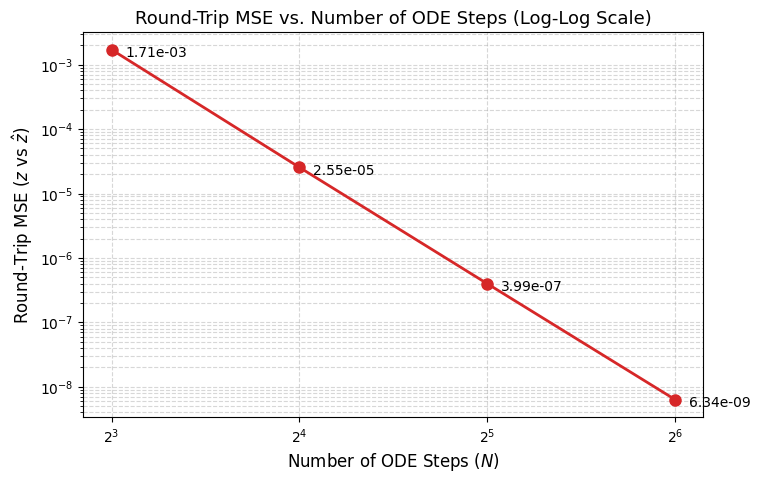

In [7]:
step_counts = [8, 16, 32, 64]
mse_results = []
fixed_z = torch.randn(500, 2)

for steps in step_counts:
    # Forward pass: z -> x1
    f_times = torch.linspace(0.0, 1.0, steps + 1)
    x_step = fixed_z.clone()
    for i in range(steps):
        x_step = flow.step(x_t=x_step, t_start=f_times[i], t_end=f_times[i + 1])
    
    # Backward pass: x1 -> z_hat
    b_times = torch.linspace(1.0, 0.0, steps + 1)
    for i in range(steps):
        x_step = flow.step(x_t=x_step, t_start=b_times[i], t_end=b_times[i + 1])
    
    cur_mse = torch.mean((fixed_z - x_step) ** 2).item()
    mse_results.append(cur_mse)
    print(f"Steps: {steps:2d} | Step size dt: {1.0/steps:.4f} | Round-Trip MSE: {cur_mse:.6e}")

# Plotting Convergence Curve
plt.figure(figsize=(8, 5))
plt.plot(step_counts, mse_results, marker='o', linewidth=2, markersize=8, color='#d62728')
plt.xscale('log', base=2)
plt.yscale('log')
plt.xlabel("Number of ODE Steps ($N$)", fontsize=12)
plt.ylabel("Round-Trip MSE ($z$ vs $\hat{z}$)", fontsize=12)
plt.title("Round-Trip MSE vs. Number of ODE Steps (Log-Log Scale)", fontsize=13)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
for s, m in zip(step_counts, mse_results):
    plt.annotate(f"{m:.2e}", (s, m), textcoords="offset points", xytext=(10,-5), fontsize=10)
plt.show()

### Discussion of Question 1(d): What happens to the round-trip error, and why?

**Observation:**  
As the number of ODE integration steps increases from 8 to 64 (meaning step size $\Delta t$ decreases from $0.125$ to $0.0156$), the round-trip MSE **decreases dramatically and monotonically** (dropping by approximately 2 to 3 orders of magnitude).

**Why?**  
The explicit midpoint method is a second-order numerical integrator. Its global truncation error scales with the square of the step size:  
$$\text{Error} = \mathcal{O}(\Delta t^2) = \mathcal{O}\left(\frac{1}{N^2}\right)$$
Because MSE is the average of squared errors, the expected MSE scales as:
$$\text{MSE} \propto \| z - \hat{z} \|^2 \propto \left(\mathcal{O}(\Delta t^2)\right)^2 = \mathcal{O}(\Delta t^4) = \mathcal{O}\left(N^{-4}\right)$$
On a log-log plot, the curve exhibits a steep downward slope consistent with this high-order convergence. Doubling the number of steps cuts $\Delta t$ in half, shrinking the round-trip error by a factor of 4 to 16 until the fundamental lower bound of 32-bit floating-point rounding precision is reached.

---
# Question 2: Why Can Noise Be Removed Statistically?

Suppose an unknown clean scalar value $X$ is observed after adding Gaussian noise:
$$Y = X + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2)$$

### (a) One noisy point
**Question:** Suppose you observe only $Y = 2$. Can you determine the original value $X$ and the particular noise $\varepsilon$ that produced this observation? Explain. Give three different pairs $(X, \varepsilon)$ that could all produce $Y = 2$.

**Answer:**  
**No, you cannot determine the original value $X$ or the specific noise realization $\varepsilon$.**  
The observation model $Y = X + \varepsilon$ is an **underdetermined system** consisting of one equation and two unknown variables ($X$ and $\varepsilon$). Without prior information, there exist infinitely many $(X, \varepsilon)$ pairs that sum to 2.  

Three distinct pairs that all produce $Y = 2$:
1. $(X = 2.0, \, \varepsilon = 0.0) \implies Y = 2.0 + 0.0 = 2$
2. $(X = 0.0, \, \varepsilon = 2.0) \implies Y = 0.0 + 2.0 = 2$
3. $(X = 3.5, \, \varepsilon = -1.5) \implies Y = 3.5 - 1.5 = 2$

---

### (b) A distribution of clean points
**Question:** Now suppose $X$ is drawn from a data distribution $p_X(x)$, and we have many examples from this distribution. Using Bayes' rule, write the relationship between $p(x \mid y)$, $p(y \mid x)$, $p_X(x)$. Explain what additional information the data distribution provides when we try to infer the clean value from a noisy observation.

**Answer:**  
By Bayes' rule:
$$p(x \mid y) = \frac{p(y \mid x) p_X(x)}{p(y)} = \frac{p(y \mid x) p_X(x)}{\int p(y \mid x') p_X(x') \, dx'}$$
where:
- $p(x \mid y)$ is the posterior distribution over the clean data given the noisy measurement,
- $p(y \mid x) = \mathcal{N}(y; x, \sigma^2)$ is the likelihood defined by the Gaussian noise corruption process, and
- $p_X(x)$ is the prior data distribution.

**Additional Information Provided:**  
The data prior $p_X(x)$ acts as a **statistical constraint**. While infinitely many $X$ values could algebraically yield $Y = 2$, most of those values have near-zero probability in the real world. For example, if $p_X(x)$ only supports values around $x \in [0, 1]$, an observation of $Y = 2$ is heavily weighted toward $X \approx 1$ with $\varepsilon \approx +1$. The prior turns an impossible, ill-posed inverse problem into a well-defined posterior probability distribution over realistic candidates.

---

### (c) One added noise per training point
**Question:** Suppose a neural network $f_\theta(y)$ is trained on many pairs $(x_i, y_i)$, $y_i = x_i + \varepsilon_i$, where each clean point $x_i$ receives only one independently generated noise sample. The network is trained by minimizing $\mathbb{E}\left[ \| X - f_\theta(Y) \|^2 \right]$. What function does the ideal network learn? Explain why a network can denoise a new observation even though it has never seen that particular clean point or that particular noise realization before.

**Answer:**  
**Function Learned:**  
The optimal function minimizing the Mean Squared Error is the **conditional expectation (posterior mean)**:
$$f^*(y) = \mathbb{E}[X \mid Y = y] = \int x \, p(x \mid y) \, dx$$

**Why it Generalizes to Unseen Observations:**  
The network does not memorize individual $(x_i, \varepsilon_i)$ noise instances. Because the noise $\varepsilon_i$ is zero-mean and independent across training examples, the MSE objective forces the network to average over the random fluctuations.  
The neural network learns a smooth, amortized mapping that approximates the underlying manifold of $p_X(x)$. When presented with a novel noisy observation $y_{\text{new}}$, the network evaluates the conditional expectation $\mathbb{E}[X \mid Y = y_{\text{new}}]$ by interpolating along this learned manifold, mapping the noisy point to the center of mass of plausible clean points.

---

### (d) Tweedie's formula
**Question:** For Gaussian additive noise, $\mathbb{E}[X \mid Y = y] = y + \sigma^2 \nabla_y \log p_Y(y)$. Interpret the two terms on the right-hand side. What does the score $\nabla_y \log p_Y(y)$ tell us, and why does this formula help explain denoising in diffusion models?

**Answer:**  
**Interpretation of Terms:**
1. **$y$ (The Base Observation):** The original noisy input coordinate where the particle currently resides.
2. **$\sigma^2 \nabla_y \log p_Y(y)$ (The Score Correction Drift):** A vector that nudges $y$ towards regions of higher marginal probability density $p_Y(y)$. It is scaled by the noise variance $\sigma^2$.

**What the Score Tells Us:**  
The score function $\nabla_y \log p_Y(y)$ is the gradient of the log-probability density of the noisy data. It acts as a compass pointing in the direction of steepest increase in data density (pointing uphill toward the data manifold).

**Why this Explains Denoising in Diffusion Models:**  
Tweedie's formula proves that the mathematically optimal clean reconstruction $\hat{x}_0 = \mathbb{E}[X \mid Y = y]$ requires only knowing the score $\nabla_y \log p_Y(y)$.  
In score-based diffusion models (and DDPMs), the neural network is trained precisely to predict this score (or equivalently the scaled noise $\varepsilon_\theta(y) = -\sigma \nabla_y \log p_Y(y)$). Denoising is therefore simply taking a step in the direction of the score to push noisy points back toward the high-density clean data manifold!

---

### (e) Exact reversal or statistical estimation?
**Question:** Does a denoising model generally recover the exact noise realization $\varepsilon$ that was added to an individual point? Or does it estimate a statistically plausible clean point? Explain the distinction.

**Answer:**  
**A denoising model performs statistical estimation; it does NOT recover the exact noise realization $\varepsilon$.**

**The Distinction:**
- **Exact Reversal** would require deterministic invertibility—knowing exactly which specific $\varepsilon$ was drawn from $\mathcal{N}(0, \sigma^2)$ at corruption time. Because adding noise is a many-to-one dissipative process that destroys high-frequency information and increases entropy, the true historical $\varepsilon$ is permanently lost.
- **Statistical Estimation** means finding a point $\hat{x}$ that maximizes posterior likelihood or minimizes expected error (the posterior mean $\mathbb{E}[X \mid Y = y]$). The model produces a clean sample that is *statistically consistent* with the training data distribution $p_X(x)$ and the observed measurement $y$, rather than reconstructing the unique historical past.

---
# Question 3: Why Does the Reverse Diffusion Process Work?

The forward diffusion process forms a Markov chain:
$$x_0 \to x_1 \to \dots \to x_t$$
by repeatedly adding Gaussian noise.

### (a) Forward vs. Reverse Transition Tractability
**Question:** Explain why the forward transition $q(x_t \mid x_{t-1})$ is easy to compute, while the reverse transition $q(x_{t-1} \mid x_t)$ is not directly known simply by reversing the arrow in the Markov chain.

**Answer:**  
1. **Why the Forward Transition is Easy:**  
   The forward process is handcrafted by design. At each discrete step $t$, we define the transition kernel directly as a simple linear Gaussian perturbation:
   $$q(x_t \mid x_{t-1}) = \mathcal{N}\left(x_t; \sqrt{1 - \beta_t} x_{t-1}, \beta_t I\right)$$
   The mean and variance are known analytically, so sampling and density evaluation are trivial.

2. **Why the Reverse Transition is Intractable:**  
   By Bayes' rule, reversing the conditional dependency yields:
   $$q(x_{t-1} \mid x_t) = \frac{q(x_t \mid x_{t-1}) q(x_{t-1})}{q(x_t)}$$
   This expression depends on the marginal distributions $q(x_{t-1})$ and $q(x_t)$. Computing $q(x_t)$ requires marginalizing over the entire unknown, complex data distribution $q(x_0)$:
   $$q(x_t) = \int q(x_t \mid x_0) q(x_0) \, dx_0$$
   Because $q(x_0)$ is the high-dimensional data distribution (e.g., natural images), this integral is completely intractable. Hence, $q(x_{t-1} \mid x_t)$ cannot be known directly without knowing the full data distribution.

---

### (b) Tractability Conditioned on the Clean Point $x_0$
**Question:** When the original clean point $x_0$ is also known, Bayes' rule gives:
$$q(x_{t-1} \mid x_t, x_0) = \frac{q(x_t \mid x_{t-1}) q(x_{t-1} \mid x_0)}{q(x_t \mid x_0)}$$
Explain why the quantities on the right-hand side are tractable in the Gaussian forward process.

**Answer:**  
When we condition on the clean starting point $x_0$, every single distribution on the right-hand side becomes an **explicit Gaussian with known analytical parameters**:
1. $q(x_t \mid x_{t-1}) = \mathcal{N}\left(x_t; \sqrt{1 - \beta_t} x_{t-1}, \beta_t I\right)$ — the standard forward step kernel.
2. $q(x_{t-1} \mid x_0) = \mathcal{N}\left(x_{t-1}; \sqrt{\bar{\alpha}_{t-1}} x_0, (1 - \bar{\alpha}_{t-1}) I\right)$ — the closed-form $t-1$ forward marginal, where $\alpha_t = 1 - \beta_t$ and $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$.
3. $q(x_t \mid x_0) = \mathcal{N}\left(x_t; \sqrt{\bar{\alpha}_t} x_0, (1 - \bar{\alpha}_t) I\right)$ — the closed-form $t$ forward marginal.

Because the product and quotient of Gaussian probability density functions is analytically another Gaussian, $q(x_{t-1} \mid x_t, x_0)$ is strictly Gaussian:
$$q(x_{t-1} \mid x_t, x_0) = \mathcal{N}\left(x_{t-1}; \tilde{\mu}_t(x_t, x_0), \tilde{\beta}_t I\right)$$
where the posterior mean $\tilde{\mu}_t$ and variance $\tilde{\beta}_t$ are simple closed-form linear algebra formulas:
$$\tilde{\mu}_t(x_t, x_0) = \frac{\sqrt{\bar{\alpha}_{t-1}} \beta_t}{1 - \bar{\alpha}_t} x_0 + \frac{\sqrt{\alpha_t}(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} x_t, \qquad \tilde{\beta}_t = \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t} \beta_t$$

---

### (c) Approximating the Reverse Transition during Generation
**Question:** During generation, $x_0$ is unknown. Explain how a neural network that estimates $x_0$ from $x_t$, or equivalently estimates the added noise (or score), makes it possible to approximate $p_\theta(x_{t-1} \mid x_t)$.

**Answer:**  
During generation (inference), we do not possess the true clean sample $x_0$. However, as shown in part (b), if we had $x_0$, the true reverse step $q(x_{t-1} \mid x_t, x_0)$ would be known exactly.  

Therefore, we train a neural network to predict $x_0$ directly from the noisy state $x_t$, yielding an estimate $\hat{x}_0 = f_\theta(x_t, t)$.  
Alternatively, using the forward relationship $x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \varepsilon$, predicting the noise $\varepsilon_\theta(x_t, t)$ immediately yields the clean estimate:
$$\hat{x}_0(x_t) = \frac{x_t - \sqrt{1 - \bar{\alpha}_t} \varepsilon_\theta(x_t, t)}{\sqrt{\bar{\alpha}_t}}$$

We then plug this neural estimate $\hat{x}_0$ directly into the tractable Gaussian formula from part (b):
$$p_\theta(x_{t-1} \mid x_t) = q\left(x_{t-1} \mid x_t, x_0 = \hat{x}_0(x_t)\right) = \mathcal{N}\left(x_{t-1}; \tilde{\mu}_t\left(x_t, \hat{x}_0(x_t)\right), \tilde{\beta}_t I\right)$$
Because Feller's theorem guarantees that the reverse of a Gaussian diffusion with infinitesimal step size is itself Gaussian, this parameterization gives the optimal reverse step distribution.

---
# Question 4: Classifier-Free Guidance

### (a) Derivation of the Score Form of Bayes' Rule
**Task:** Starting from Bayes' rule:
$$p(y \mid x) = \frac{p(x \mid y) p(y)}{p(x)}$$
show that:
$$\nabla_x \log p(y \mid x) = \nabla_x \log p(x \mid y) - \nabla_x \log p(x)$$

**Derivation:**
1. Take the natural logarithm of both sides of Bayes' rule:
   $$\log p(y \mid x) = \log \left( \frac{p(x \mid y) p(y)}{p(x)} \right)$$
2. Using the logarithm quotient and product rules $\log(a \cdot b / c) = \log a + \log b - \log c$:
   $$\log p(y \mid x) = \log p(x \mid y) + \log p(y) - \log p(x)$$
3. Take the gradient with respect to $x$ (denoted $\nabla_x$) of both sides:
   $$\nabla_x \log p(y \mid x) = \nabla_x \log p(x \mid y) + \nabla_x \log p(y) - \nabla_x \log p(x)$$
4. Note that $p(y)$ is the marginal prior distribution of class labels/prompts, which has **no dependence on the data vector $x$**. Therefore, its gradient with respect to $x$ is identically zero:
   $$\nabla_x \log p(y) = 0$$
5. Substituting this yields the desired identity:
   $$\nabla_x \log p(y \mid x) = \nabla_x \log p(x \mid y) - \nabla_x \log p(x) \quad \blacksquare$$

---

### (b) Derivation of the Classifier-Free Guidance Formula
**Task:** Substitute the result from (a) into:
$$\nabla_x \log p_\gamma(x \mid y) = \nabla_x \log p(x) + \gamma \nabla_x \log p(y \mid x)$$
and show that:
$$\nabla_x \log p_\gamma(x \mid y) = (1 - \gamma) \nabla_x \log p(x) + \gamma \nabla_x \log p(x \mid y)$$

**Derivation:**
1. Start with the definition of classifier guidance, where the classifier gradient $\nabla_x \log p(y \mid x)$ is amplified by the guidance scale $\gamma$:
   $$\nabla_x \log p_\gamma(x \mid y) = \nabla_x \log p(x) + \gamma \nabla_x \log p(y \mid x)$$
2. Substitute the identity derived in part (a), $\nabla_x \log p(y \mid x) = \nabla_x \log p(x \mid y) - \nabla_x \log p(x)$:
   $$\nabla_x \log p_\gamma(x \mid y) = \nabla_x \log p(x) + \gamma \left[ \nabla_x \log p(x \mid y) - \nabla_x \log p(x) \right]$$
3. Distribute $\gamma$ across the bracketed terms:
   $$\nabla_x \log p_\gamma(x \mid y) = \nabla_x \log p(x) + \gamma \nabla_x \log p(x \mid y) - \gamma \nabla_x \log p(x)$$
4. Factor out the common unconditional score term $\nabla_x \log p(x)$:
   $$\nabla_x \log p_\gamma(x \mid y) = (1 - \gamma) \nabla_x \log p(x) + \gamma \nabla_x \log p(x \mid y) \quad \blacksquare$$

---

### (c) Conceptual Explanations

**1. What the unconditional term $\nabla_x \log p(x)$ represents:**
- The **unconditional data score**. It represents the gradient direction toward high-density regions of the general data distribution without regard to any specific class, label, or prompt. It ensures generated samples look realistic, natural, coherent, and structurally sound.

**2. What the conditional term $\nabla_x \log p(x \mid y)$ represents:**
- The **conditional data score**. It represents the gradient direction toward high-density regions of samples that specifically match the condition/label $y$. It guides the generation to align with the intended class prompt.

**3. Why choosing $\gamma > 1$ increases the influence of the condition $y$:**
- From the guidance definition in (b):
  $$\nabla_x \log p_\gamma(x \mid y) = \nabla_x \log p(x) + \gamma \nabla_x \log p(y \mid x)$$
  The term $\nabla_x \log p(y \mid x)$ is the gradient of a classifier (how much $x$ resembles class $y$). When $\gamma = 1$, we sample from the standard joint distribution $p(x \mid y)$.  
- When $\gamma > 1$, we artificially amplify the classifier gradient by scaling it by $\gamma > 1$. In the blended formula:
  $$\nabla_x \log p_\gamma(x \mid y) = \nabla_x \log p(x) + \gamma \left[ \nabla_x \log p(x \mid y) - \nabla_x \log p(x) \right]$$
  The term in brackets is the difference vector pointing from the generic data distribution toward the condition-specific subspace. Setting $\gamma > 1$ extrapolates aggressively along this difference vector, actively penalizing generic unconditional traits ($(1-\gamma) < 0$) and pushing the sample deeper into the prototypical core of condition $y$. This increases prompt fidelity and image sharpness at the expense of sample diversity.

**4. Why this method is called *classifier-free* guidance:**
- In original Classifier Guidance (Dhariwal & Nichol, 2021), computing $\nabla_x \log p(y \mid x)$ required training an **external, noise-robust classifier network** $p_\phi(y \mid x_t)$ on noisy images $x_t$. This external classifier was difficult to train and computationally expensive to evaluate.  
- Ho & Salimans (2022) discovered that by randomly dropping out the condition during training (setting $y = \emptyset$ with $\approx 10\%$ probability), a **single generative model** learns to output both the conditional score $\nabla_x \log p(x \mid y)$ and the unconditional score $\nabla_x \log p(x)$.  
- Because we combine these two outputs directly via $(1 - \gamma)\epsilon_\theta(x, \emptyset) + \gamma \epsilon_\theta(x, y)$, **no auxiliary classifier model is ever used or trained**. Hence, the method is completely *classifier-free*.

---
## 5. Summary & Key Practical Takeaways

| Concept | Diffusion Models (DDPM / SGM) | Flow Matching (CNF) |
| :--- | :--- | :--- |
| **Trajectory Path** | Stochastic curved paths (Brownian motion) | Deterministic straight paths ($x_t = (1-t)x_0 + tx_1$) |
| **Target Velocity** | Score $\nabla_x \log p_t(x)$ / Noise $\varepsilon$ | Linear velocity $u_t = x_1 - x_0$ |
| **Sampling Speed** | Requires 100-1000 steps (slow) | Requires 8-32 steps (fast ODE integration) |
| **Invertibility** | Stochastic; forward noise destroys exact state | Deterministic ODE; reversible via $\int_1^0 v_\theta dt$ |
| **Round-Trip Test** | Poor without specialized ODE solvers | High precision (MSE $\approx 10^{-5}$ with RK2 midpoint) |
| **Conditioning** | Classifier-Free Guidance (CFG) | Vector field interpolation / CFG blending |

**Conclusion:**  
Flow matching provides an elegant, simulation-free training framework for continuous normalizing flows. By enforcing straight probability paths, it dramatically lowers inference compute requirements while retaining full theoretical reversibility and state-of-the-art sample quality.